# Quality, denominators and threshold sensitivity

This notebook adds the diagnostic checks required to interpret historical trends. It checks all monthly summary observations and compares alternative analytical windows on the full January 2026 file. The sensitivity experiment describes one month, not every historical month.

In [1]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Resolve paths independently of whether Jupyter starts in the repo or notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists() and (p / "src/nyc_taxi").is_dir())
RAW = Path(os.environ.get("NYC_TAXI_RAW_DIR", str(Path.home() / "Data/raw/nyc-taxi")))
SUMMARY = Path(os.environ.get("NYC_TAXI_SUMMARY", str(Path.home() / "Data/processed/nyc-taxi/monthly_summary.parquet")))
FIGURES = ROOT / "reports/figures"


In [2]:
from nyc_taxi.validation import validate_monthly_summary
from nyc_taxi.config import AnalysisConfig
from nyc_taxi.pipeline import prepare_trips
from nyc_taxi.aggregation import aggregate_monthly_summary

df = pd.read_parquet(SUMMARY)
validate_monthly_summary(df, "2015-01", "2026-08")
print("Validated observations:", len(df))
print("Raw records:", int(df.raw_record_count.sum()))
print("In-period records:", int(df.trip_count.sum()))
print("Outside nominal month:", int(df.outside_period_count.sum()))
display(df.filter(regex="coverage_pct$").describe().T)

Validated observations: 140
Raw records: 831256595
In-period records: 831237097
Outside nominal month: 19498


,count,mean,std,min,25%,50%,75%,max
duration_coverage_pct,140.0,99.578736,0.388173,98.346496,99.619321,99.715621,99.783267,99.883028
distance_coverage_pct,140.0,98.528576,0.920555,96.348111,97.955595,98.784313,99.334319,99.456441
speed_coverage_pct,140.0,98.089864,1.185122,94.982273,97.750039,98.478174,99.040086,99.257193
monetary_coverage_pct,140.0,99.064778,1.689509,90.539410,99.139664,99.564382,99.947863,99.968087
passenger_coverage_pct,140.0,94.001314,8.454981,69.900996,92.832669,97.057528,99.999017,99.999765
ratecode_coverage_pct,140.0,93.535247,9.131645,66.933482,92.824833,96.630321,99.996682,99.999064


## 1. Monetary exclusions and extreme positive records

Excluded signed totals can be negative. The monetary alert threshold is a diagnostic, not automatic deletion. A small count of outliers can still influence sums much more than medians.

In [3]:
diagnostics = df[["year", "month", "monetary_valid_count", "monetary_excluded_count", "monetary_outlier_count", "monetary_outlier_amount_sum", "valid_monetary_total_amount_sum", "finite_signed_total_amount_sum", "excluded_monetary_total_amount_sum", "max_valid_total_amount"]].copy()
diagnostics["outlier_share_of_selected_sum_pct"] = diagnostics.monetary_outlier_amount_sum.fillna(0) / diagnostics.valid_monetary_total_amount_sum * 100
display(diagnostics.sort_values("outlier_share_of_selected_sum_pct", ascending=False).head(15))
display(diagnostics.loc[diagnostics.year.eq(2026) & diagnostics.month.eq(1)].T)

,year,month,monetary_valid_count,monetary_excluded_count,monetary_outlier_count,monetary_outlier_amount_sum,valid_monetary_total_amount_sum,finite_signed_total_amount_sum,excluded_monetary_total_amount_sum,max_valid_total_amount,outlier_share_of_selected_sum_pct
64,2020,5,346863,1529,24,444744.24,6.875483e+06,6.854513e+06,-20969.87,429562.25,6.468552
69,2020,10,1673740,7360,16,1008530.10,3.046389e+07,3.036420e+07,-99692.69,998325.61,3.310576
62,2020,3,2996228,11033,26,1687588.17,5.683672e+07,5.666332e+07,-173402.45,1000003.80,2.969186
0,2015,1,12736969,4066,68,4007908.68,1.925393e+08,1.924960e+08,-43243.26,3950611.60,2.081606
71,2020,12,1454132,7731,13,413398.29,2.583348e+07,2.572613e+07,-107347.68,398467.70,1.600243
20,2016,9,10111417,4601,56,2653878.63,1.737579e+08,1.737037e+08,-54245.98,647567.44,1.527342
80,2021,9,2951288,12400,14,826035.16,6.205206e+07,6.185131e+07,-200744.41,818286.74,1.331197
74,2021,3,1915963,9156,8,410231.27,3.461763e+07,3.449710e+07,-120526.32,398469.20,1.185036
42,2018,7,7844707,5919,67,1536498.62,1.303016e+08,1.302310e+08,-70555.48,730923.96,1.179187
48,2019,1,7688798,7282,55,1419822.09,1.217587e+08,1.216789e+08,-79780.86,623261.66,1.166095


,132
year,2.026000e+03
month,1.000000e+00
monetary_valid_count,3.684858e+06
monetary_excluded_count,4.002400e+04
monetary_outlier_count,8.400000e+01
monetary_outlier_amount_sum,5.681783e+04
valid_monetary_total_amount_sum,1.098996e+08
finite_signed_total_amount_sum,1.086865e+08
excluded_monetary_total_amount_sum,-1.213096e+06
max_valid_total_amount,2.560200e+03


## 2. Understand why averages of medians differ from pooled medians

This deliberately tiny example makes the distinction visible without loading historical trip records.

In [4]:
month_a = pd.Series([1, 1, 1])
month_b = pd.Series([100])
print("Average of monthly medians:", pd.Series([month_a.median(), month_b.median()]).mean())
print("Pooled median of individual values:", pd.concat([month_a, month_b]).median())
print("Monthly summaries cannot reconstruct the exact pooled median.")

Average of monthly medians: 50.5
Pooled median of individual values: 1.0
Monthly summaries cannot reconstruct the exact pooled median.


## 3. Full-month sensitivity experiment — January 2026

Compare tighter, default and wider trip windows. Keep the monetary alert unchanged. Counts and medians reveal how much the conclusions depend on the window. Source rows are never modified.

,duration_valid_count,distance_valid_count,speed_valid_count,median_duration_min,median_distance_mi,median_speed_mph
configuration,,,,,,
Tighter,3664733,3597864,3537554,13.45,1.9,9.434298
Default,3675289,3598765,3549552,13.50,1.9,9.434944
Wider,3678057,3598982,3552759,13.50,1.9,9.433428


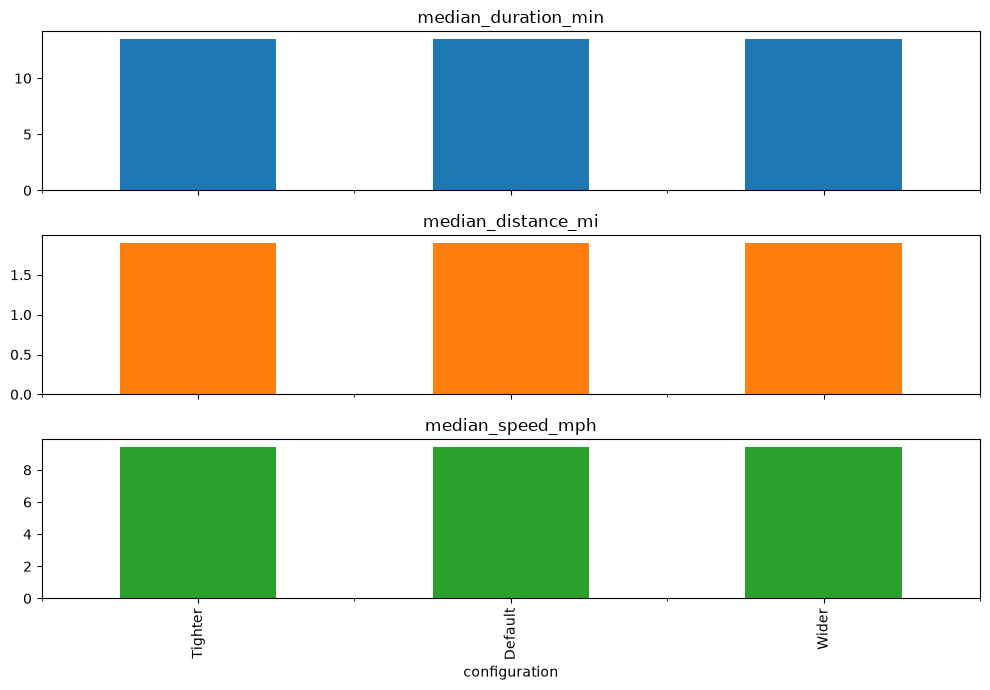

In [5]:
raw = pd.read_parquet(RAW / "yellow/2026/yellow_tripdata_2026-01.parquet")
zones = pd.read_csv(RAW / "taxi_zone_lookup.csv")
configurations = {
    "Tighter": AnalysisConfig(max_duration_min=90, max_distance_mi=40, max_speed_mph=50),
    "Default": AnalysisConfig(),
    "Wider": AnalysisConfig(max_duration_min=180, max_distance_mi=100, max_speed_mph=80),
}
rows = []
for name, config in configurations.items():
    prepared = prepare_trips(raw, zones, 2026, 1, config)
    result = aggregate_monthly_summary(prepared, 2026, 1)
    result["configuration"] = name
    rows.append(result)
    del prepared
sensitivity = pd.concat(rows, ignore_index=True).set_index("configuration")
columns = ["duration_valid_count", "distance_valid_count", "speed_valid_count", "median_duration_min", "median_distance_mi", "median_speed_mph"]
display(sensitivity[columns])
sensitivity[["median_duration_min", "median_distance_mi", "median_speed_mph"]].plot.bar(subplots=True, figsize=(10, 7), legend=False, layout=(3, 1))
plt.tight_layout()
plt.show()

## 4. What remains uncertain

Threshold sensitivity is not proof that retained records are correct. The checkpoint uses source size and modification time as a fast change detector, not a cryptographic checksum of raw data. The zone lookup uses a content hash. Exact multi-month pooled medians require trip-level recomputation. No causal traffic model, inflation adjustment or demand forecasting is claimed here.

Run `python scripts/schema_audit.py` to inspect all source schemas, and `python scripts/validate_monthly_summary.py` to repeat the summary checks.